<a href="https://colab.research.google.com/github/NathaliaVal08/analisis-depresion-estudiantes/blob/main/notebooks/analisis_depresion_estudiantes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 Factores asociados a la depresión en estudiantes universitarios

**Autora:** Nathalia Stefania Valbuena Moreno · Analista de Datos Junior

**Fuente de datos:** [Student Depression Detection Dataset – Kaggle](https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset)

### Contexto de negocio
Una universidad quiere **priorizar sus programas de bienestar estudiantil** (consejería, grupos de apoyo, becas) con un presupuesto limitado. Para eso necesita saber **qué perfiles de estudiantes reportan depresión con mayor frecuencia** y dónde una intervención puede tener más impacto.

### Preguntas que guían el análisis
1. ¿Qué porcentaje de estudiantes reporta depresión?
2. ¿Qué factores sociales, económicos y académicos se asocian más con la depresión?
3. ¿Qué tan fuerte es cada asociación? ¿Es estadísticamente significativa?
4. ¿Qué perfiles de estudiantes deberían priorizarse?

> ⚠️ **Nota ética:** este análisis es exploratorio y **no es un diagnóstico clínico**. Los resultados muestran *asociaciones*, no causas, y no deben usarse para etiquetar a personas.

## 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency, mannwhitneyu

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

# Carpeta donde se guardan los gráficos que usa el README
IMG_DIR = Path("../images")
IMG_DIR.mkdir(exist_ok=True)

def guardar(fig, nombre):
    """Guarda la figura en /images para reutilizarla en el README."""
    fig.savefig(IMG_DIR / f"{nombre}.png", bbox_inches="tight")

## 2. Carga de datos
El notebook funciona igual en local y en Google Colab: si no encuentra el archivo en la carpeta `data/`, lo lee directamente desde GitHub.

In [2]:
RUTA_LOCAL = Path("../data/raw/Student_Depression_Dataset.csv")
RUTA_GITHUB = ("https://raw.githubusercontent.com/NathaliaVal08/analisis-depresion-estudiantes/"
               "main/data/raw/Student_Depression_Dataset.csv")

df_raw = pd.read_csv(RUTA_LOCAL if RUTA_LOCAL.exists() else RUTA_GITHUB)
print(f"Filas: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 4,464 | Columnas: 13


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


### Diccionario de datos

| Columna original | Columna en español | Descripción |
|---|---|---|
| Gender | genero | Género del estudiante |
| Age | edad | Edad en años |
| Family_background | nivel_socioeconomico | Clase media-baja, media o alta |
| Relationship_status | situacion_sentimental | Soltero(a), en una relación o complicado |
| Marital_status | estado_civil | Soltero(a), casado(a) o separado(a) |
| Living_style | convivencia | Vive solo(a) (*Bachelor*) o con la familia |
| Current_semester | semestre | Semestre que cursa |
| CGPA | promedio | Promedio académico acumulado (escala 0–4) |
| friend_circle | circulo_amigos | Tiene o no círculo de amigos |
| Health_condition | estado_salud | Estado de salud autorreportado |
| Cost_without_study | gasto_mensual | Gasto mensual sin incluir matrícula (moneda local) |
| Home_division | region | Región de origen (Bangladesh) |
| Depression | depresion | Reporta depresión (variable objetivo) |

## 3. Información general y calidad de datos

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


In [4]:
calidad = pd.DataFrame({
    "nulos": df_raw.isnull().sum(),
    "% nulos": (df_raw.isnull().mean() * 100).round(2),
    "valores_unicos": df_raw.nunique(),
})
print(f"Registros duplicados: {df_raw.duplicated().sum()}")
calidad

Registros duplicados: 0


,nulos,% nulos,valores_unicos
Gender,0,0.0,2
Age,0,0.0,12
Family_background,0,0.0,3
Relationship_status,0,0.0,3
Marital_status,0,0.0,3
Living_style,0,0.0,2
Current_semester,0,0.0,14
CGPA,0,0.0,169
friend_circle,0,0.0,2
Health_condition,0,0.0,4


In [5]:
df_raw.describe().round(2)

,Age,Current_semester,CGPA,Cost_without_study
count,4464.00,4464.00,4464.00,4464.00
mean,22.62,5.40,3.41,11242.98
std,2.02,2.58,0.39,6640.14
min,17.00,0.00,2.25,0.00
25%,21.00,3.00,3.15,6100.00
50%,23.00,5.00,3.49,9500.00
75%,24.00,7.00,3.70,15439.00
max,28.00,13.00,4.00,32000.00


No hay valores nulos ni duplicados. Aun así, revisamos **reglas de negocio**, porque un dato puede estar completo y ser inconsistente:

In [6]:
inconsistencias = {
    "Semestre = 0": (df_raw["Current_semester"] == 0).sum(),
    "Gasto mensual = 0": (df_raw["Cost_without_study"] == 0).sum(),
    "Situación 'Single' pero estado civil 'Married'": ((df_raw["Relationship_status"] == "Single")
                                                       & (df_raw["Marital_status"] == "Married")).sum(),
}
pd.Series(inconsistencias, name="registros").to_frame()

,registros
Semestre = 0,42
Gasto mensual = 0,2
Situación 'Single' pero estado civil 'Married',201


**Interpretación:**
- 42 estudiantes aparecen en **semestre 0** (posiblemente admitidos que aún no inician) y 2 tienen **gasto mensual 0**. Son pocos y se conservan, pero se documentan.
- 201 estudiantes figuran como *"Single"* en situación sentimental y a la vez *"Married"* en estado civil. Esto sugiere que las dos preguntas se interpretaron distinto en la encuesta. Por eso analizaremos ambas variables por separado y con cautela.

## 4. Preparación de datos

In [7]:
df = df_raw.rename(columns={
    "Gender": "genero", "Age": "edad", "Family_background": "nivel_socioeconomico",
    "Relationship_status": "situacion_sentimental", "Marital_status": "estado_civil",
    "Living_style": "convivencia", "Current_semester": "semestre", "CGPA": "promedio",
    "friend_circle": "circulo_amigos", "Health_condition": "estado_salud",
    "Cost_without_study": "gasto_mensual", "Home_division": "region", "Depression": "depresion",
})

traducciones = {
    "genero": {"Female": "Mujer", "Male": "Hombre"},
    "nivel_socioeconomico": {"Lower Middle class": "Media-baja", "Middle class": "Media", "Rich class": "Alta"},
    "situacion_sentimental": {"Single": "Soltero(a)", "In a Relationship": "En una relación", "Complicated": "Complicado"},
    "estado_civil": {"Unmarried": "Soltero(a)", "Married": "Casado(a)", "Separated": "Separado(a)"},
    "convivencia": {"Bachelor": "Solo(a)", "Family": "Con familia"},
    "circulo_amigos": {"Yes": "Sí", "No": "No"},
    "estado_salud": {"Good": "Buena", "Normal": "Normal", "Abnormal": "Anormal", "Critical": "Crítica"},
    "depresion": {"Yes": "Sí", "No": "No"},
}
for col, mapa in traducciones.items():
    df[col] = df[col].map(mapa)

# Variable numérica para calcular tasas (1 = reporta depresión)
df["depresion_flag"] = (df["depresion"] == "Sí").astype(int)

# Rangos de promedio académico
df["rango_promedio"] = pd.cut(df["promedio"], bins=[0, 3.0, 3.25, 3.5, 3.75, 4.0],
                              labels=["≤3.00", "3.01–3.25", "3.26–3.50", "3.51–3.75", "3.76–4.00"],
                              include_lowest=True)

# Orden lógico de las categorías para los gráficos
ORDEN = {
    "nivel_socioeconomico": ["Media-baja", "Media", "Alta"],
    "estado_salud": ["Buena", "Normal", "Anormal", "Crítica"],
}
df.head()

,genero,edad,nivel_socioeconomico,situacion_sentimental,estado_civil,convivencia,semestre,promedio,circulo_amigos,estado_salud,gasto_mensual,region,depresion,depresion_flag,rango_promedio
0,Mujer,22,Media,Soltero(a),Soltero(a),Solo(a),8,3.43,Sí,Crítica,10113,Chittagong,Sí,1,3.26–3.50
1,Hombre,19,Media,Soltero(a),Soltero(a),Solo(a),2,3.70,Sí,Anormal,13815,Chittagong,Sí,1,3.51–3.75
2,Hombre,23,Media,Soltero(a),Soltero(a),Con familia,8,3.28,No,Anormal,15450,Dhaka,Sí,1,3.26–3.50
3,Hombre,20,Media,Complicado,Soltero(a),Con familia,2,3.77,No,Buena,17413,Dhaka,No,0,3.76–4.00
4,Mujer,21,Media,Soltero(a),Soltero(a),Con familia,1,4.00,No,Anormal,16693,Dhaka,Sí,1,3.76–4.00


## 5. Variable objetivo: ¿cuántos estudiantes reportan depresión?

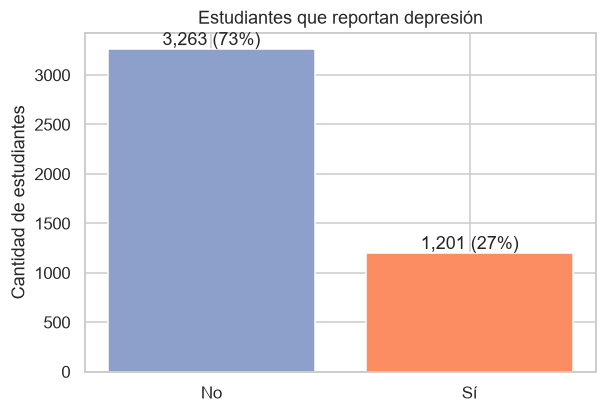

Tasa general de depresión: 26.9%


In [8]:
TASA_GENERAL = df["depresion_flag"].mean()

fig, ax = plt.subplots(figsize=(6, 4))
conteo = df["depresion"].value_counts()
ax.bar(conteo.index, conteo.values, color=["#8da0cb", "#fc8d62"])
for i, v in enumerate(conteo.values):
    ax.text(i, v + 40, f"{v:,} ({v / len(df):.0%})", ha="center")
ax.set_title("Estudiantes que reportan depresión")
ax.set_ylabel("Cantidad de estudiantes")
guardar(fig, "01_distribucion_depresion")
plt.show()
print(f"Tasa general de depresión: {TASA_GENERAL:.1%}")

**Interpretación:** aproximadamente **1 de cada 4 estudiantes (26.9%)** reporta depresión. Esta tasa general será la **línea de referencia**: los grupos que estén por encima merecen más atención.

## 6. Tasa de depresión por factor
Creamos una función reutilizable para no repetir código en cada gráfico.

In [9]:
def tasa_por_grupo(columna):
    """Devuelve la tasa de depresión y la cantidad de estudiantes por categoría."""
    tabla = (df.groupby(columna, observed=True)["depresion_flag"]
               .agg(tasa="mean", estudiantes="size"))
    if columna in ORDEN:
        return tabla.reindex(ORDEN[columna])
    return tabla.sort_values("tasa", ascending=False)


def graficar_tasa(columna, titulo, ax):
    """Gráfico de barras con la tasa por grupo y la línea de la tasa general."""
    tabla = tasa_por_grupo(columna)
    # Naranja solo si el grupo supera la tasa general en más de 1 punto porcentual
    colores = ["#fc8d62" if t > TASA_GENERAL + 0.01 else "#8da0cb" for t in tabla["tasa"]]
    ax.bar(tabla.index.astype(str), tabla["tasa"], color=colores)
    ax.axhline(TASA_GENERAL, color="gray", linestyle="--", linewidth=1)
    for i, (t, n) in enumerate(zip(tabla["tasa"], tabla["estudiantes"])):
        ax.text(i, t + 0.01, f"{t:.0%}\n(n={n:,})", ha="center", fontsize=8)
    ax.set_title(titulo)
    ax.set_ylim(0, max(tabla["tasa"].max() * 1.3, 0.5))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    ax.tick_params(axis="x", rotation=15)

### 6.1 Factores sociales

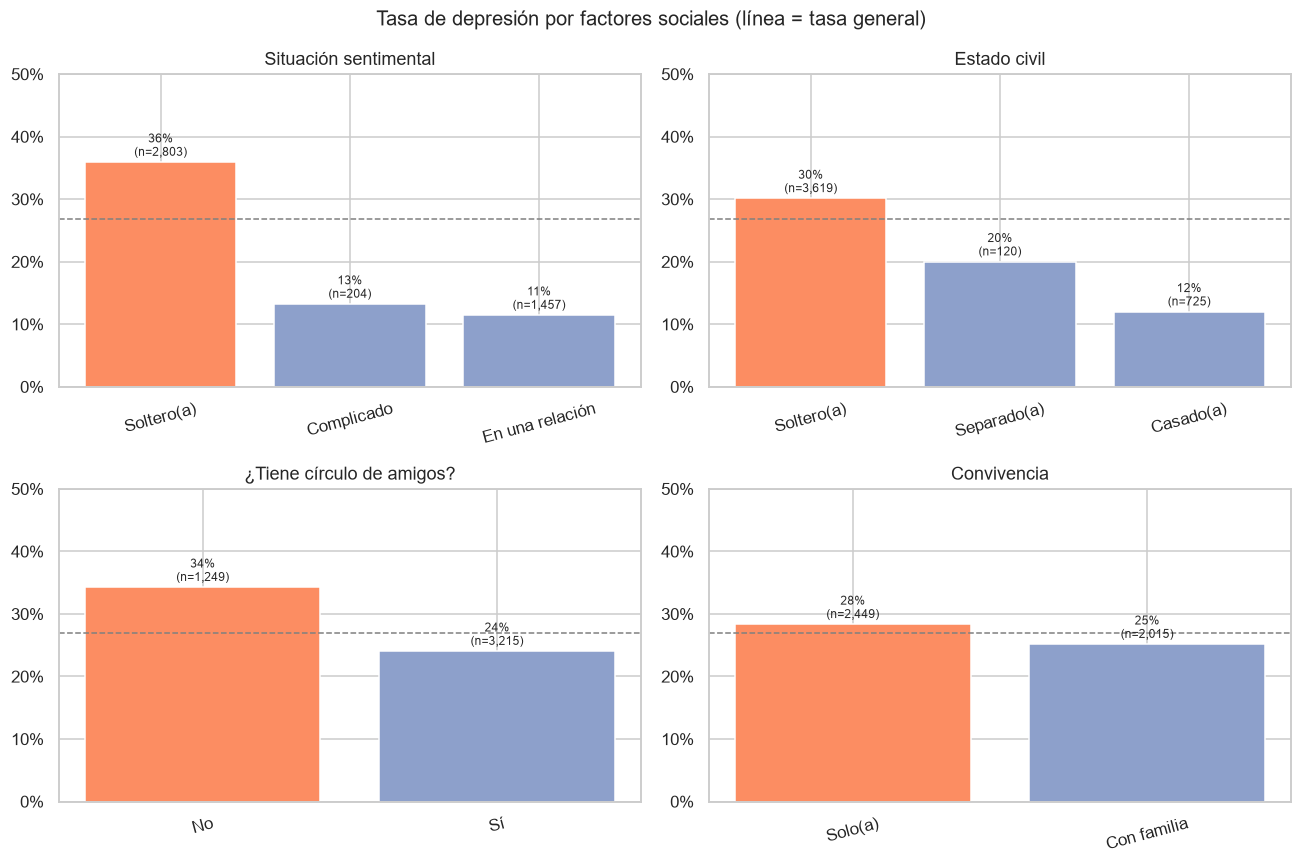

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
graficar_tasa("situacion_sentimental", "Situación sentimental", axes[0, 0])
graficar_tasa("estado_civil", "Estado civil", axes[0, 1])
graficar_tasa("circulo_amigos", "¿Tiene círculo de amigos?", axes[1, 0])
graficar_tasa("convivencia", "Convivencia", axes[1, 1])
fig.suptitle("Tasa de depresión por factores sociales (línea = tasa general)", fontsize=13)
fig.tight_layout()
guardar(fig, "02_factores_sociales")
plt.show()

**Interpretación:**
- La **situación sentimental** es el factor social con mayor diferencia: los estudiantes **solteros(as) reportan 36%**, frente a **11% de quienes están en una relación**, es decir, **3 veces más**.
- **No tener círculo de amigos** eleva la tasa a **34%**, frente a **24%** de quienes sí lo tienen.
- Las personas **casadas** reportan la tasa más baja (**12%**).
- Vivir solo(a) o con la familia muestra una diferencia pequeña (28% vs. 25%).

👉 Las redes de apoyo (pareja, amigos) aparecen como un factor protector importante.

### 6.2 Factores socioeconómicos y demográficos

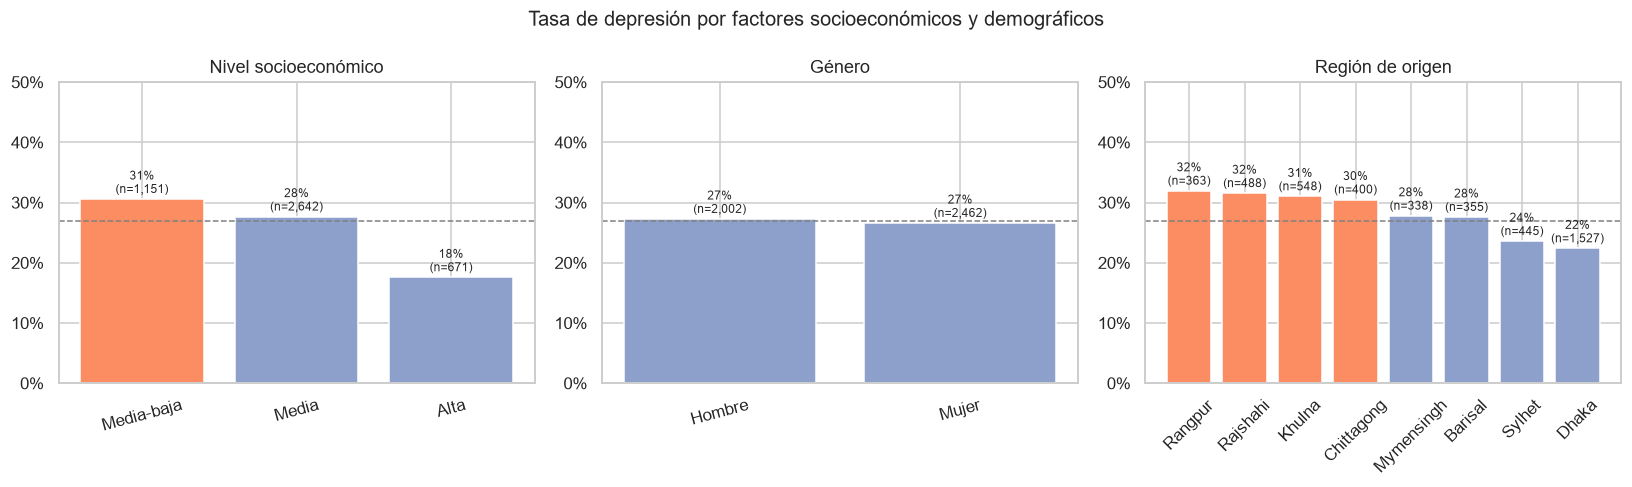

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
graficar_tasa("nivel_socioeconomico", "Nivel socioeconómico", axes[0])
graficar_tasa("genero", "Género", axes[1])
graficar_tasa("region", "Región de origen", axes[2])
axes[2].tick_params(axis="x", rotation=45)
fig.suptitle("Tasa de depresión por factores socioeconómicos y demográficos", fontsize=13)
fig.tight_layout()
guardar(fig, "03_factores_socioeconomicos")
plt.show()

**Interpretación:**
- La tasa **disminuye a medida que sube el nivel socioeconómico**: 31% en clase media-baja, 28% en media y 18% en alta.
- **No hay diferencia por género** (27% en ambos casos).
- Por región, **Dhaka (la capital) tiene la tasa más baja (22%)**, mientras Rangpur, Rajshahi y Khulna superan el 31%.

👉 Los apoyos económicos (becas, subsidios) y la atención en regiones fuera de la capital pueden tener impacto.

### 6.3 Factores académicos y económicos

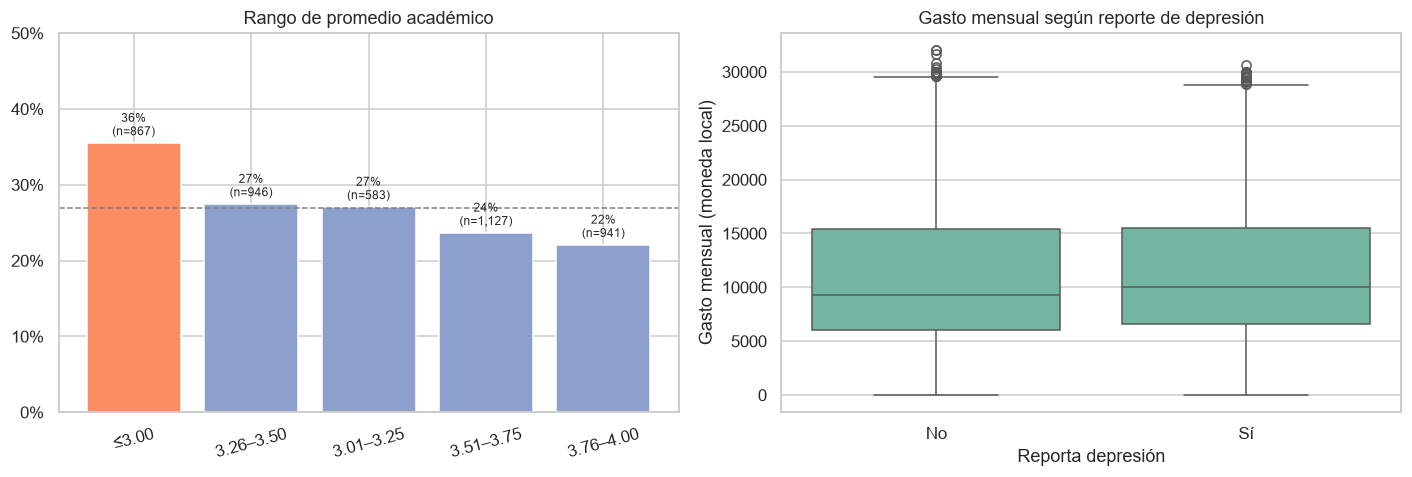

,promedio,gasto_mensual,edad,semestre
depresion,,,,
No,3.50,9300.0,23.0,5.0
Sí,3.42,10000.0,23.0,5.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
graficar_tasa("rango_promedio", "Rango de promedio académico", axes[0])

sns.boxplot(data=df, x="depresion", y="gasto_mensual", order=["No", "Sí"], ax=axes[1])
axes[1].set_title("Gasto mensual según reporte de depresión")
axes[1].set_xlabel("Reporta depresión")
axes[1].set_ylabel("Gasto mensual (moneda local)")
fig.tight_layout()
guardar(fig, "04_factores_academicos")
plt.show()

df.groupby("depresion")[["promedio", "gasto_mensual", "edad", "semestre"]].median()

**Interpretación:**
- Los estudiantes con **promedio de 3.0 o menos** reportan depresión en un **36%**, frente a **22%** en el rango más alto (3.76–4.00).
- El **gasto mensual** es muy similar entre ambos grupos, así que no parece un factor diferenciador.
- Edad y semestre tienen medianas iguales en ambos grupos.

👉 El bajo rendimiento académico puede servir como **señal de alerta temprana** para remitir a bienestar.

## 7. ¿Qué tan fuerte es cada asociación?
Un gráfico puede mostrar diferencias por azar. Para confirmarlo usamos:
- **Prueba chi-cuadrado:** indica si la diferencia es estadísticamente significativa (p < 0.05).
- **V de Cramér:** mide la fuerza de la asociación de 0 (ninguna) a 1 (total). Como guía: < 0.1 débil, 0.1–0.3 moderada, > 0.3 fuerte.

In [13]:
def v_cramer(columna):
    tabla = pd.crosstab(df[columna], df["depresion_flag"])
    chi2, p, _, _ = chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    return pd.Series({"V de Cramér": round(v, 3), "p-valor": p})

factores = ["estado_salud", "situacion_sentimental", "estado_civil", "rango_promedio",
            "circulo_amigos", "nivel_socioeconomico", "region", "convivencia", "genero"]
fuerza = pd.DataFrame({f: v_cramer(f) for f in factores}).T.sort_values("V de Cramér", ascending=False)
fuerza["¿Significativo?"] = np.where(fuerza["p-valor"] < 0.05, "Sí", "No")
fuerza["p-valor"] = fuerza["p-valor"].map(lambda p: f"{p:.1e}")
fuerza

,V de Cramér,p-valor,¿Significativo?
estado_salud,0.813,0.0e+00,Sí
situacion_sentimental,0.264,1.7e-68,Sí
estado_civil,0.153,2.9e-23,Sí
rango_promedio,0.106,3.8e-10,Sí
circulo_amigos,0.103,6.1e-12,Sí
nivel_socioeconomico,0.093,4.8e-09,Sí
region,0.090,7.5e-06,Sí
convivencia,0.035,1.9e-02,Sí
genero,0.007,6.4e-01,No


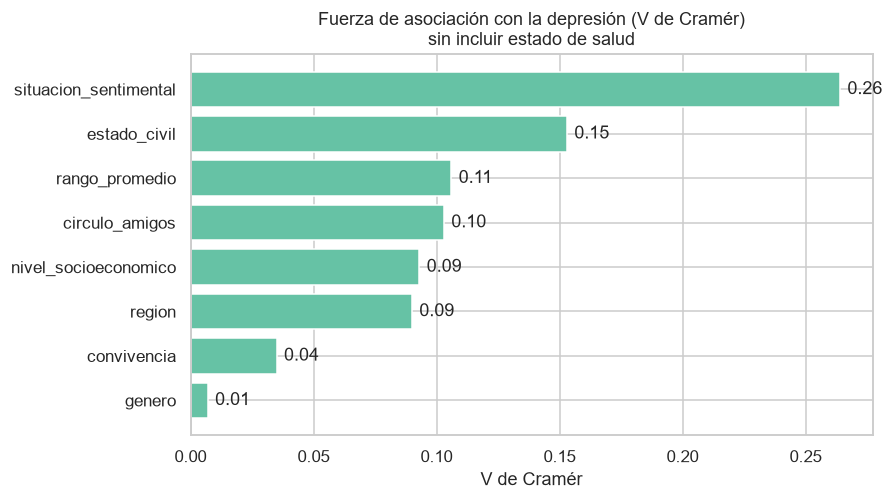

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
datos = fuerza["V de Cramér"].drop("estado_salud").sort_values()
ax.barh(datos.index, datos.values, color="#66c2a5")
for i, v in enumerate(datos.values):
    ax.text(v + 0.003, i, f"{v:.2f}", va="center")
ax.set_title("Fuerza de asociación con la depresión (V de Cramér)\nsin incluir estado de salud")
ax.set_xlabel("V de Cramér")
guardar(fig, "05_fuerza_asociacion")
plt.show()

**Interpretación:**
- **Situación sentimental (0.26)** y **estado civil (0.15)** son las asociaciones más fuertes entre los factores sociales.
- Promedio, círculo de amigos y nivel socioeconómico tienen una asociación **moderada-débil pero significativa**.
- **Género no es significativo** (p = 0.64): no hay evidencia de diferencia entre hombres y mujeres.

### ⚠️ Alerta de calidad: el estado de salud

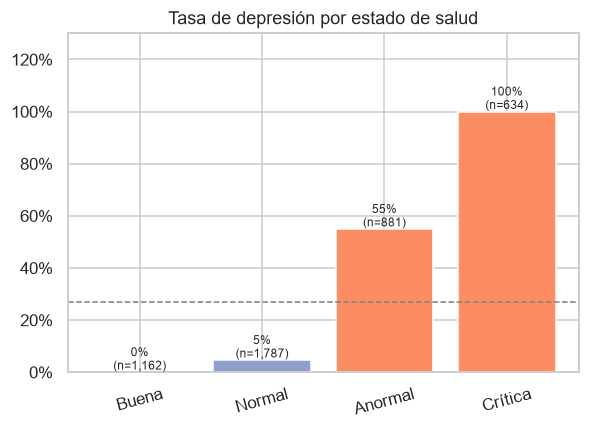

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
graficar_tasa("estado_salud", "Tasa de depresión por estado de salud", ax)
guardar(fig, "06_estado_salud")
plt.show()

**Interpretación:** el estado de salud tiene una V de Cramér de **0.81**, casi perfecta: **el 100% de quienes tienen salud "Crítica" reporta depresión y el 0% de quienes tienen salud "Buena"**. En datos reales una relación tan exacta es muy rara.

Esto sugiere que la variable se construyó **a partir del mismo diagnóstico** o que el dataset es **sintético**. Si se usara en un modelo predictivo, generaría una **fuga de información (data leakage)**: el modelo parecería excelente pero no serviría en la práctica. Por eso **se excluye del ranking de factores**.

## 8. Perfiles de riesgo para priorizar

In [16]:
perfiles = {
    "Todos los estudiantes": df["depresion_flag"] == df["depresion_flag"],
    "En relación + con amigos": (df["situacion_sentimental"] != "Soltero(a)") & (df["circulo_amigos"] == "Sí"),
    "Soltero(a)": df["situacion_sentimental"] == "Soltero(a)",
    "Soltero(a) + sin amigos": (df["situacion_sentimental"] == "Soltero(a)") & (df["circulo_amigos"] == "No"),
    "Soltero(a) + sin amigos + clase media-baja": ((df["situacion_sentimental"] == "Soltero(a)")
                                                   & (df["circulo_amigos"] == "No")
                                                   & (df["nivel_socioeconomico"] == "Media-baja")),
}
resumen = pd.DataFrame({
    nombre: {"estudiantes": mascara.sum(), "tasa_depresion": df.loc[mascara, "depresion_flag"].mean()}
    for nombre, mascara in perfiles.items()
}).T
resumen["veces_vs_general"] = (resumen["tasa_depresion"] / TASA_GENERAL).round(1)
resumen["estudiantes"] = resumen["estudiantes"].astype(int)
resumen.style.format({"tasa_depresion": "{:.0%}", "veces_vs_general": "{:.1f}x"})

,estudiantes,tasa_depresion,veces_vs_general
Todos los estudiantes,4464,27%,1.0x
En relación + con amigos,1186,9%,0.3x
Soltero(a),2803,36%,1.3x
Soltero(a) + sin amigos,774,44%,1.6x
Soltero(a) + sin amigos + clase media-baja,171,46%,1.7x


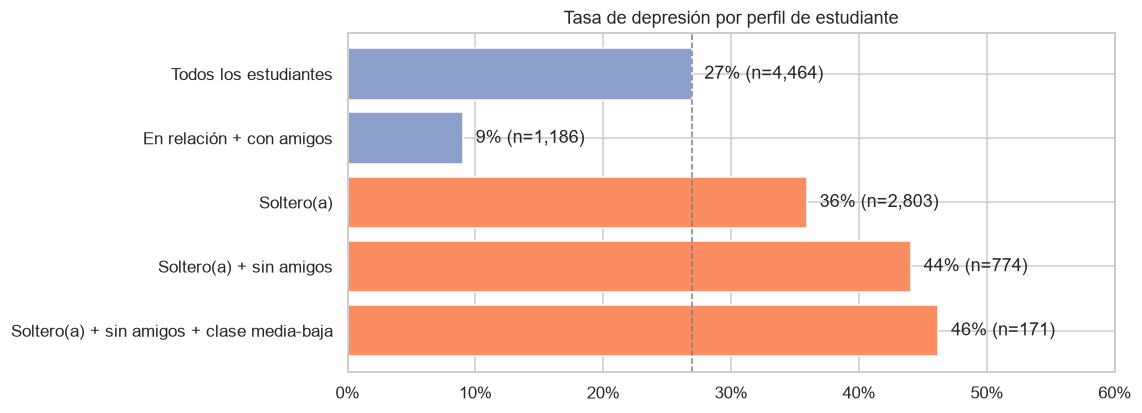

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
colores = ["#fc8d62" if t > TASA_GENERAL else "#8da0cb" for t in resumen["tasa_depresion"]]
ax.barh(resumen.index, resumen["tasa_depresion"], color=colores)
ax.axvline(TASA_GENERAL, color="gray", linestyle="--", linewidth=1)
for i, (t, n) in enumerate(zip(resumen["tasa_depresion"], resumen["estudiantes"])):
    ax.text(t + 0.01, i, f"{t:.0%} (n={n:,})", va="center")
ax.invert_yaxis()
ax.set_xlim(0, 0.6)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_title("Tasa de depresión por perfil de estudiante")
guardar(fig, "07_perfiles_riesgo")
plt.show()

**Interpretación:** combinar factores permite **focalizar mejor**:
- Los estudiantes **solteros(as) y sin círculo de amigos (774 personas)** reportan depresión en un **44%**, es decir, **1.6 veces la tasa general**.
- Si además son de **clase media-baja**, la tasa sube a **46%**.
- En cambio, quienes tienen **pareja y amigos** reportan solo un **9%**.

👉 Un programa dirigido a estos ~770 estudiantes llegaría a una población con 1.6 veces la prevalencia de una campaña general, y casi 5 veces la del grupo con pareja y amigos.

## 9. Conclusiones y recomendaciones

### Principales hallazgos
1. **26.9%** de los estudiantes reporta depresión (1 de cada 4).
2. Las **redes de apoyo** son el factor social más asociado: solteros(as) 36% vs. en relación 11%; sin amigos 34% vs. con amigos 24%.
3. El **nivel socioeconómico** importa: clase alta 18% vs. media-baja 31%.
4. Un **promedio ≤ 3.0** se asocia con una tasa de 36%, frente a 22% en los mejores promedios.
5. **No hay diferencias por género.**
6. El **estado de salud** presenta una relación casi perfecta con la depresión, posible fuga de información.

### Recomendaciones para bienestar universitario
| Prioridad | Acción | Población objetivo |
|---|---|---|
| 🔴 Alta | Grupos de integración y mentorías entre pares | Estudiantes sin círculo de amigos |
| 🔴 Alta | Alertas tempranas desde el área académica hacia bienestar | Estudiantes con promedio ≤ 3.0 |
| 🟠 Media | Ampliar becas y apoyo económico con acompañamiento psicológico | Clase media-baja |
| 🟠 Media | Llevar programas de bienestar a regiones fuera de la capital | Rangpur, Rajshahi, Khulna, Chittagong |

### Limitaciones
- Los datos son **autorreportados y de un solo momento**; no permiten hablar de causalidad.
- La variable de estado de salud parece **derivada del objetivo** o el dataset puede ser **sintético**.
- Hay **inconsistencias** entre situación sentimental y estado civil (201 registros).
- La población corresponde a estudiantes de **Bangladesh**; los resultados no se pueden generalizar directamente a otros países.

### Próximos pasos
- Construir un **modelo de clasificación** (regresión logística) **sin** la variable de salud, para estimar el riesgo de forma interpretable.
- Crear un **dashboard en Power BI** para que bienestar universitario filtre por perfil y región.